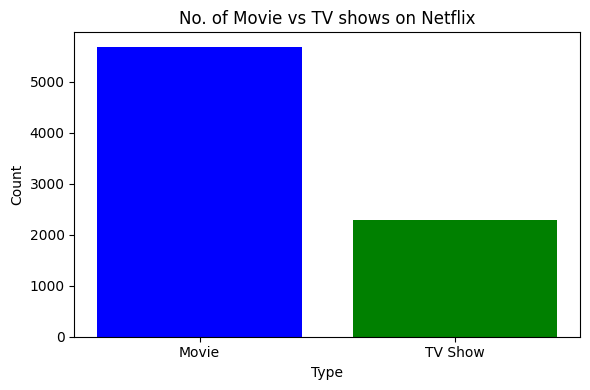

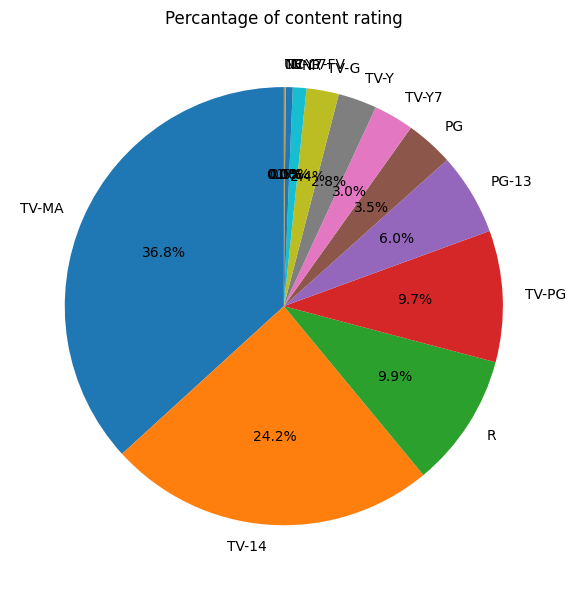

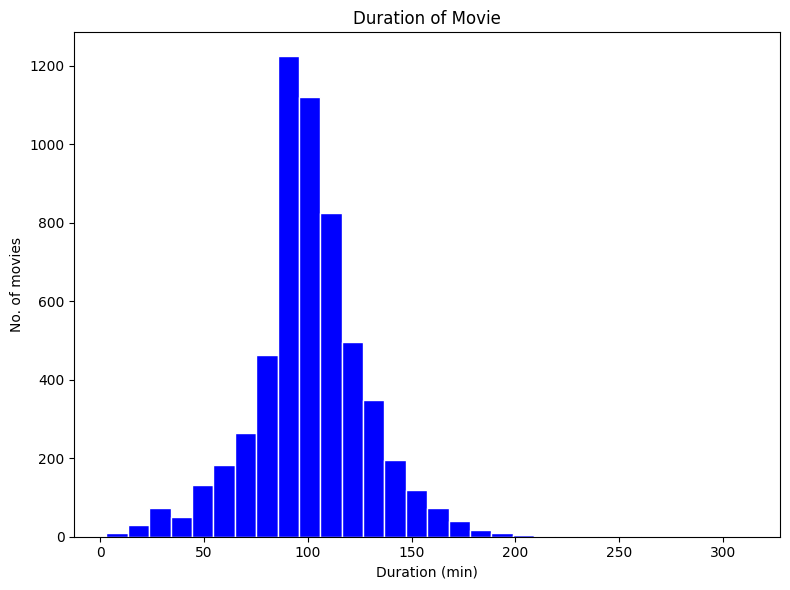

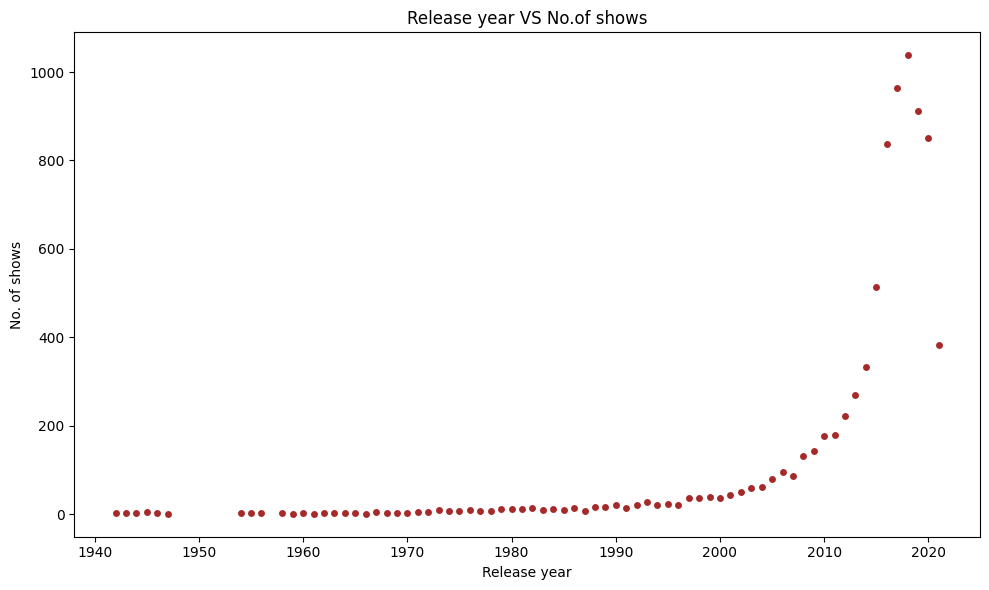

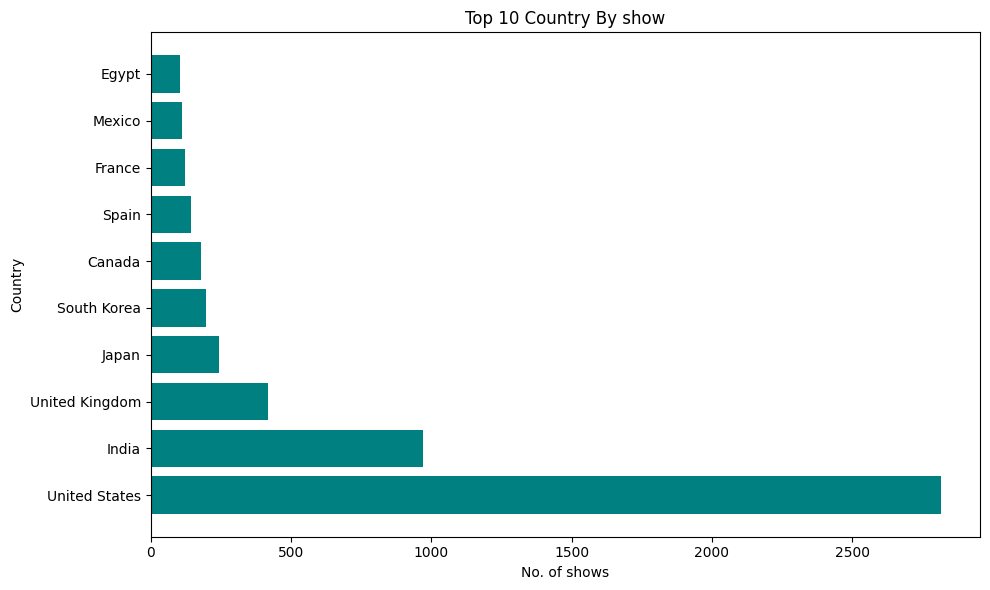

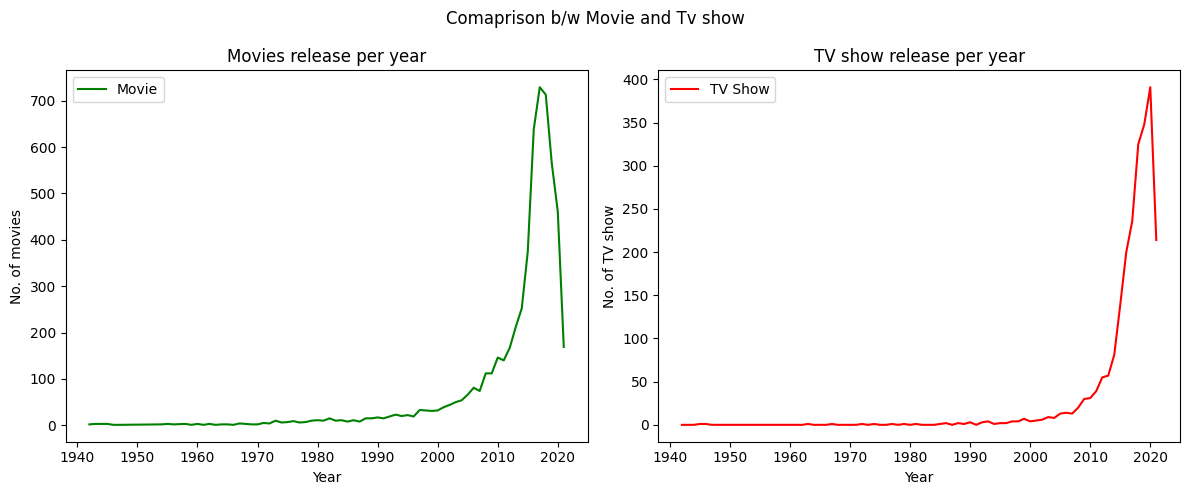

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel('netflix_dataset.xlsx')

df = df.dropna(subset=['type','release_year','rating','country','duration'])

type_counts=df['type'].value_counts()
plt.figure(figsize=(6,4))
plt.bar(type_counts.index, type_counts.values, color=['blue','green'])
plt.title('No. of Movie vs TV shows on Netflix')
plt.xlabel('Type')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('Movies_VS_TVshow.png')
plt.show()

rating_count =df['rating'].value_counts()
plt.figure(figsize=(8,6))
plt.pie(rating_count, labels=rating_count.index, autopct='%1.1f%%', startangle=90)
plt.title('Percantage of content rating')
plt.tight_layout()
plt.savefig('Contenet_rating_pie.png')
plt.show()

movie_df=df[df['type']=='Movie'].copy()
movie_df['duration_int']=movie_df['duration'].str.replace(' min','').astype(int)
plt.figure(figsize=(8,6))
plt.hist(movie_df['duration_int'], bins=30, color='blue', edgecolor='white')
plt.title('Duration of Movie')
plt.xlabel('Duration (min)')
plt.ylabel('No. of movies')
plt.tight_layout()
plt.savefig('Movie_duration_hist.png')
plt.show()

release_count = df['release_year'].value_counts().sort_index()
plt.figure(figsize=(10,6))
plt.scatter(release_count.index, release_count.values, color='brown', edgecolors='white')
plt.title('Release year VS No.of shows')
plt.xlabel('Release year')
plt.ylabel('No. of shows')
plt.tight_layout()
plt.savefig('release_year_scatter.png')
plt.show()

country_count = df['country'].value_counts().head(10)
plt.figure(figsize=(10,6))
plt.barh(country_count.index, country_count.values, color='teal')
plt.title('Top 10 Country By show')
plt.xlabel('No. of shows')
plt.ylabel('Country')
plt.tight_layout()
plt.savefig('Top10_coutry.png')
plt.show()

content_by_year = df.groupby(['release_year', 'type']).size().unstack().fillna(0)
fig, ax = plt.subplots(1,2, figsize=(12,5))

ax[0].plot(content_by_year.index, content_by_year['Movie'], color='green', label='Movie')
ax[0].set_title('Movies release per year')
ax[0].set_xlabel('Year')
ax[0].set_ylabel('No. of movies')
ax[0].legend()

ax[1].plot(content_by_year.index, content_by_year['TV Show'], color='red', label='TV Show')
ax[1].set_title('TV show release per year')
ax[1].set_xlabel('Year')
ax[1].set_ylabel('No. of TV show')
ax[1].legend()

fig.suptitle('Comaprison b/w Movie and Tv show')
plt.tight_layout()
plt.savefig('movie_TVshow_comparison.png')
plt.show()


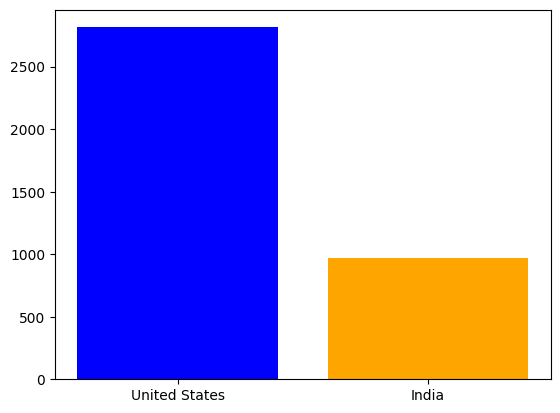

In [5]:
us = (df['country'] == 'United States').sum()
india = (df['country'] == 'India').sum()

plt.bar(['United States', 'India'], [us, india],
        color=['blue', 'orange'])

plt.show()
